# 08 · Geometric error model: tilt and rotation (paper Sec. *Geometric sensitivity*, Eq. *tilt_error*; R1.4 / R2.2)

1. **Analytic model.** The scale error from out-of-plane tilt φ is Δs/s ≈ 1/cos φ − 1 (paper Eq. *tilt_error*).
2. **Measured: in-plane rotation.** The `roll/` captures (≈15° in-plane) against the reference pose.
3. **Out-of-plane tilt (pitch / yaw).** Tilt is estimated from the four detected corners, and the analytic model gives the error it implies.
   It also shows which tilted captures pass the gates (the blind spot).
4. **Appendix.** The empirical fit in the first revision draft, and why it is not used.

| | |
|---|---|
| **Inputs** | `data/raw/robustness/` |
| **Outputs** | `results/figures/fig_tilt_error.png`, `fig_tilt_estimate.png`; `results/tables/tilt_error.csv`, `tilt_estimate.csv` |
| **Runtime** | ~20 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


## 1 · Analytic model

In [ ]:
from visioncrack.error_model import tilt_scale_error, fit_tilt_model
phi = np.array([1, 2, 5, 10, 15, 20])
model = pd.DataFrame({'phi_deg': phi, 'exact_%': 100 * tilt_scale_error(phi),
                      'approx_phi2/2_%': 100 * tilt_scale_error(phi, exact=False)})
model['ET-1 error (mm)'] = 0.55 * model['exact_%'] / 100
model['ET-5 error (mm)'] = 2.75 * model['exact_%'] / 100
model.to_csv(TAB / 'tilt_error.csv', index=False)
# values quoted in the manuscript: 2° ≈ 0.06 %, 5° ≈ 0.38 %, 10° ≈ 1.5 %
assert [round(v, 2) for v in model.set_index('phi_deg').loc[[2, 5], 'exact_%']] == [0.06, 0.38]
assert round(model.set_index('phi_deg').loc[10, 'exact_%'], 1) == 1.5
model.round(4)

,phi_deg,exact_%,approx_phi2/2_%,ET-1 error (mm),ET-5 error (mm)
0,1,0.0152,0.0152,0.0001,0.0004
1,2,0.0610,0.0609,0.0003,0.0017
2,5,0.3820,0.3808,0.0021,0.0105
3,10,1.5427,1.5231,0.0085,0.0424
4,15,3.5276,3.4269,0.0194,0.0970
5,20,6.4178,6.0923,0.0353,0.1765


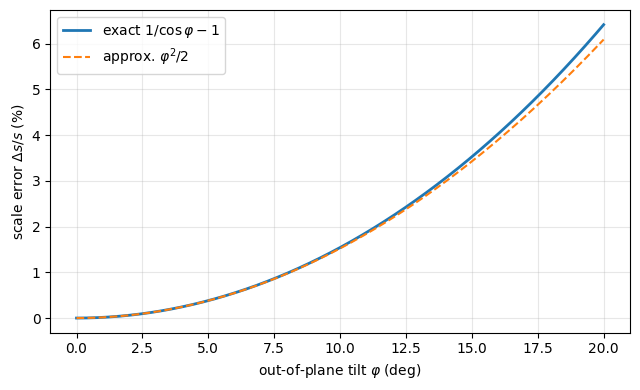

In [ ]:
p = np.linspace(0, 20, 200)
plt.figure(figsize=(6.5, 4))
plt.plot(p, 100 * tilt_scale_error(p), lw=2, label=r'exact $1/\cos\varphi-1$')
plt.plot(p, 100 * tilt_scale_error(p, exact=False), '--', lw=1.5, label=r'approx. $\varphi^2/2$')
plt.xlabel(r'out-of-plane tilt $\varphi$ (deg)'); plt.ylabel(r'scale error $\Delta s/s$ (%)')
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig(FIG / 'fig_tilt_error.png', dpi=200); plt.show()

## 2 · Measured: in-plane rotation
The `roll/` captures have a measured in-plane rotation of ≈15° (from the red frame). Their reference-bar error is about three times
that of the reference pose. All of them are rejected by the 2° rotation gate.

In [ ]:
from visioncrack import sweep
res, ref = sweep.run_all()
rot = res[res.folder.isin(['norm', 'roll']) & res.ref_found]
tab = rot.groupby('folder').agg(n=('file', 'size'), inplane_deg=('inplane_deg', 'mean'),
                                ref_mae_mm=('ref_mae', 'mean')).reindex(['norm', 'roll'])
assert np.allclose(tab.ref_mae_mm.round(3), [0.061, 0.197])
tab.round(3)

,n,inplane_deg,ref_mae_mm
folder,,,
norm,4,0.438,0.061
roll,12,15.039,0.197


## 3 · Out-of-plane tilt from the four corners
Tilt shortens one pair of label sides by ≈ cos φ. Distance shrinks all sides equally, so the **aspect ratio** (height / width)
cancels it: cos φ ≈ aspect / aspect_norm for pitch, and aspect_norm / aspect for yaw.
The analytic model then gives the scale error each capture would carry.

In [ ]:
from visioncrack import detection as det, gates
rows = []
for r in res[res.folder.isin(['norm', 'pitch', 'yaw'])].itertuples():
    c = det.find_corners(sweep.label_crop(vc.read_rgb(r.path), r))
    if c is None:
        rows.append({'folder': r.folder, 'file': r.file, 'corners': False}); continue
    q = c.as_array().astype(float)
    w = (abs(q[1, 0] - q[0, 0]) + abs(q[3, 0] - q[2, 0])) / 2
    h = (abs(q[2, 1] - q[0, 1]) + abs(q[3, 1] - q[1, 1])) / 2
    rows.append({'folder': r.folder, 'file': r.file, 'corners': True, 'w': w, 'h': h, 'aspect': h / w, 'q': q})
tilt = pd.DataFrame(rows)
nm = tilt[tilt.folder == 'norm']; a0, W0, H0 = nm.aspect.mean(), nm.w.mean(), nm.h.mean()
cosphi = np.where(tilt.folder == 'yaw', a0 / tilt.aspect, tilt.aspect / a0)
tilt['phi_est_deg'] = np.degrees(np.arccos(np.clip(cosphi, -1, 1)))
tilt['scale_err_%'] = 100 * tilt_scale_error(tilt.phi_est_deg)
tilt['accepted'] = [gates.evaluate(q, W0, H0).accepted if ok else False for ok, q in zip(tilt.corners, tilt.q)]
tilt.drop(columns='q').to_csv(TAB / 'tilt_estimate.csv', index=False, float_format='%.4f')
tilt.groupby('folder')[['phi_est_deg', 'scale_err_%']].describe().round(2).T

folder             norm  pitch    yaw
phi_est_deg count  4.00    5.0  12.00
            mean   2.86    0.0  22.66
            std    3.30    0.0   7.58
            min    0.00    0.0  13.10
            25%    0.00    0.0  18.54
            50%    2.81    0.0  19.59
            75%    5.67    0.0  26.64
            max    5.80    0.0  41.51
scale_err_% count  4.00    5.0  12.00
            mean   0.25    0.0   9.73
            std    0.29    0.0   8.36
            min    0.00    0.0   2.67
            25%    0.00    0.0   5.47
            50%    0.24    0.0   6.15
            75%    0.49    0.0  11.90
            max    0.51    0.0  33.54

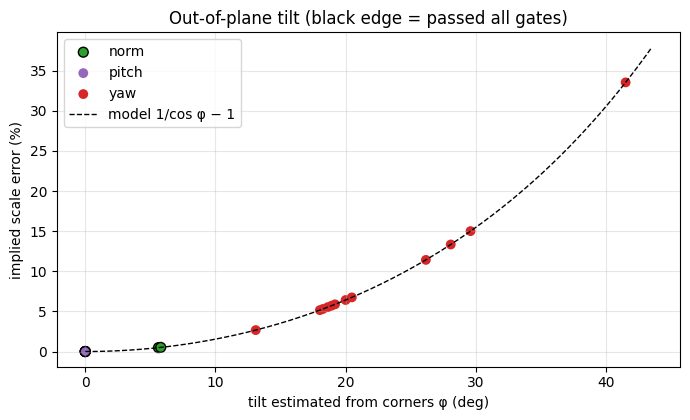

tilted captures accepted by the gates: 2; estimated φ = [0.0, 0.0]°, implied scale error ≤ 0.00 %


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for f, col in [('norm', '#2ca02c'), ('pitch', '#9467bd'), ('yaw', '#d62728')]:
    g = tilt[(tilt.folder == f) & tilt.corners]
    ax.scatter(g.phi_est_deg, g['scale_err_%'], c=col, s=50, label=f, edgecolor=['k' if a else 'none' for a in g.accepted])
pp = np.linspace(0, max(25, tilt.phi_est_deg.max() + 2), 200)
ax.plot(pp, 100 * tilt_scale_error(pp), 'k--', lw=1, label='model 1/cos φ − 1')
ax.set(xlabel='tilt estimated from corners φ (deg)', ylabel='implied scale error (%)',
       title='Out-of-plane tilt (black edge = passed all gates)')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.savefig(FIG / 'fig_tilt_estimate.png', dpi=200); plt.show()
acc = tilt[tilt.accepted & (tilt.folder != 'norm')]
print(f'tilted captures accepted by the gates: {len(acc)}; estimated φ = {acc.phi_est_deg.round(1).tolist()}°, '
      f'implied scale error ≤ {acc["scale_err_%"].max():.2f} %')

**Reading this.**
* **Noise floor ≈ 6°.** The reference-pose captures themselves estimate at 0–5.8°, so tilts below ~6° (scale error < 0.6 %) cannot be resolved this way.
* **Yaw** captures estimate at 13–42° and are all rejected by the coverage gate.
* **Pitch** captures that keep their corners show **no measurable foreshortening** (aspect ≥ norm, φ ≈ 0°), although the phone's sensor read ≈15°.
  The sensor angle is therefore not the label tilt. The two accepted pitch captures are *not* evidence of an accepted tilted label.
  The other six lose a corner and are rejected.
* So in this set, no accepted capture shows tilt above the ≈ 6° noise floor. The gates still do not measure φ directly;
  a homography from the four corners would bound it explicitly (future work in the paper).

## 4 · Appendix: the fit in the first revision draft (not used)
The draft fitted MAE(φ) = w₀ + k(1 − cos φ) and reported w₀ = 0.093 mm, k = 0.239 mm, R² = 0.89, crossing 0.10 mm at 14°.
It is reproduced below, but it should **not** be reported:
* the fitted captures are the in-plane `roll/` set (measured rotation ≈15°, section 2), not out-of-plane tilt;
* the φ axis is `|pose_a|`, a phone-sensor reading (12–78°) that does not match the measured rotation;
* the out-of-plane captures have no resolvable reference bars in this chain, so they cannot be fitted this way.

In [ ]:
A = res[res.folder.isin(['norm', 'roll']) & res.ref_found].copy()
A['phi_sensor'] = np.where(A.folder == 'norm', 0.0, A.pose_a.abs())
tf = fit_tilt_model(A.phi_sensor, A.ref_mae)
assert (round(tf.w0, 4), round(tf.k, 4), round(tf.r2, 2), round(tf.phi_at(0.10), 1)) == (0.0926, 0.2394, 0.89, 14.3)
g = A[A.folder == 'roll']
print(f'draft fit reproduced: w0={tf.w0:.4f}, k={tf.k:.4f}, R²={tf.r2:.2f}')
print(f'but: sensor |pose_a| spans {g.phi_sensor.min():.0f}–{g.phi_sensor.max():.0f}°, '
      f'measured in-plane rotation spans {g.inplane_deg.min():.1f}–{g.inplane_deg.max():.1f}°')

draft fit reproduced: w0=0.0926, k=0.2394, R²=0.89
but: sensor |pose_a| spans 12–78°, measured in-plane rotation spans 14.1–16.2°
